# Lab 7 – Laplacian Sharpening & Mathematical / Statistical Filters

In [1]:
import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('images', exist_ok=True)
for f in ['moon.jpg', 'noise.jpg', 'salt&Pepper.jpg']:
    if os.path.exists(f) and not os.path.exists(f'images/{f}'):
        shutil.copy(f, f'images/{f}')

np.random.seed(0)  # reproducible noise

def show_side_by_side(images, titles, cmap='gray'):
    fig, ax = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    for a, im, t in zip(ax, images, titles):
        if im.dtype == np.uint8:
            a.imshow(im, cmap=cmap, vmin=0, vmax=255)
        else:
            a.imshow(im, cmap=cmap)
        a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

## Part A: Laplacian Filter (Image Sharpening)

### Task#1: Manual Laplacian kernel with `filter2D`
The kernel `[[0,1,0],[1,-4,1],[0,1,0]]` has a **negative** centre, so the sharpened image is `g = f - ∇²f`. The arithmetic is done in float and clipped, avoiding the uint8 wrap-around of `img + laplacian`.

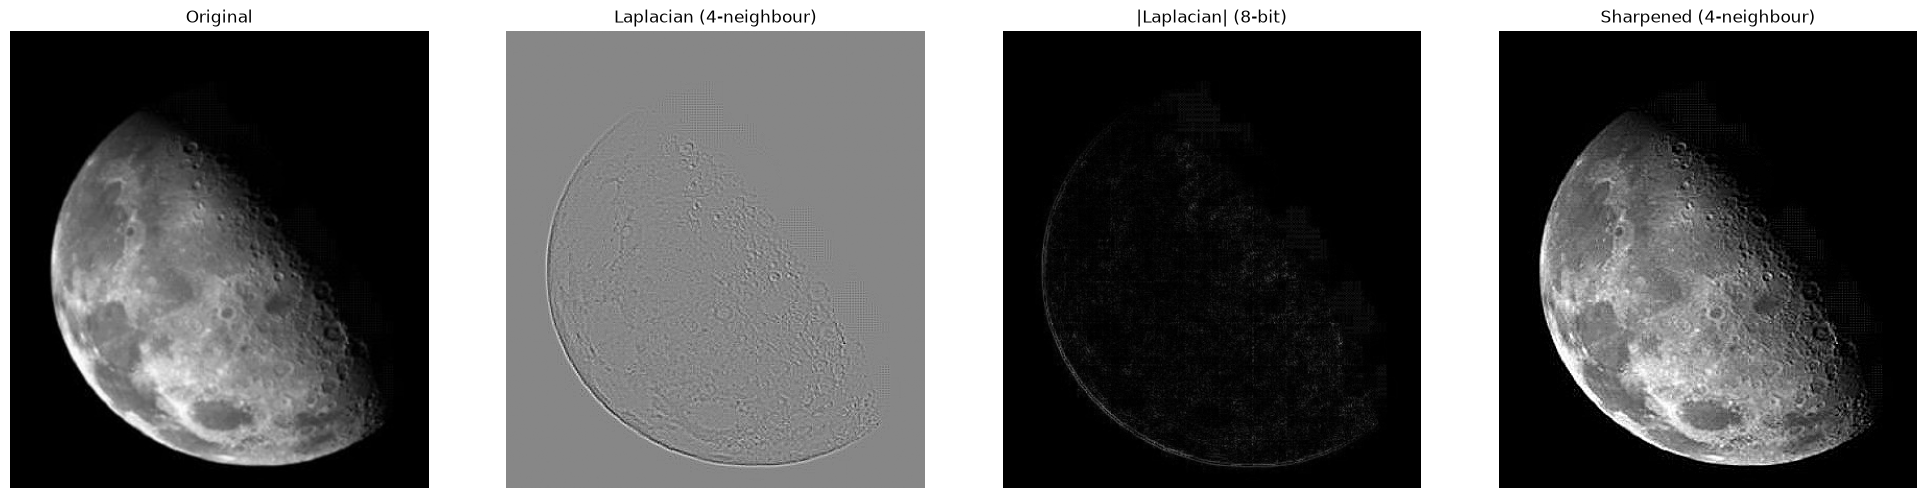

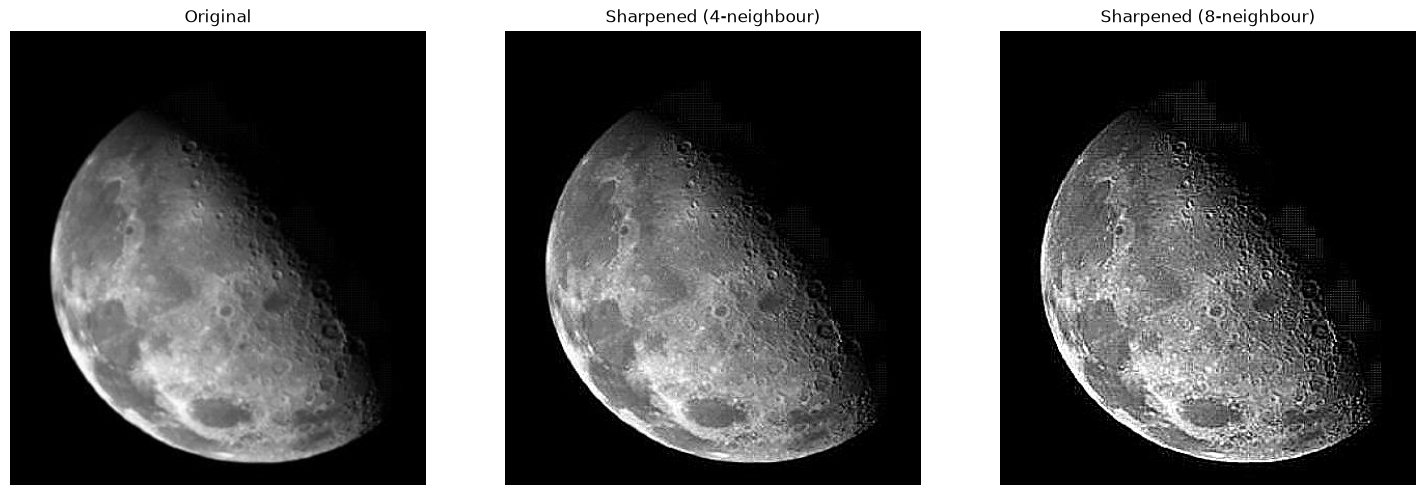

In [2]:
img = cv2.imread('images/moon.jpg', 0)

kernel_4 = np.array([[0,  1, 0],
                     [1, -4, 1],
                     [0,  1, 0]], dtype=np.float32)
kernel_8 = np.array([[1,  1, 1],
                     [1, -8, 1],
                     [1,  1, 1]], dtype=np.float32)  # also detects diagonal edges

def laplacian_sharpen(image, kernel, c=-1):
    lap = cv2.filter2D(image, cv2.CV_64F, kernel)
    sharp = np.clip(image.astype(np.float64) + c * lap, 0, 255).astype(np.uint8)
    return lap, sharp

lap4, sharp4 = laplacian_sharpen(img, kernel_4)
lap8, sharp8 = laplacian_sharpen(img, kernel_8)

show_side_by_side([img, lap4, cv2.convertScaleAbs(lap4), sharp4],
                  ['Original', 'Laplacian (4-neighbour)', '|Laplacian| (8-bit)', 'Sharpened (4-neighbour)'])
show_side_by_side([img, sharp4, sharp8],
                  ['Original', 'Sharpened (4-neighbour)', 'Sharpened (8-neighbour)'])

### Task#2: Built-in `cv2.Laplacian` with Gaussian pre-smoothing
Blurring first suppresses noise so that tiny variations are not amplified as edges.

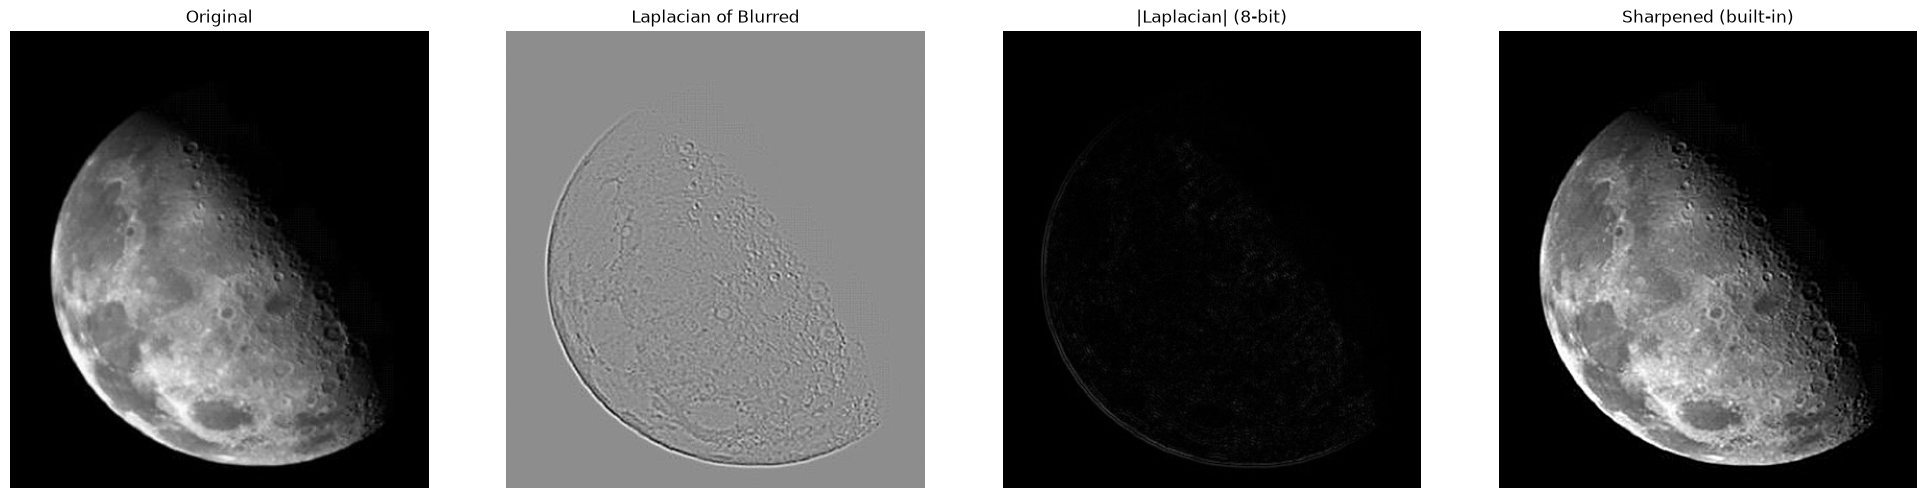

In [3]:
blurred = cv2.GaussianBlur(img, (3, 3), 0)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)  # uses the -4 centre kernel (ksize=1)
sharp_builtin = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

show_side_by_side([img, laplacian, cv2.convertScaleAbs(laplacian), sharp_builtin],
                  ['Original', 'Laplacian of Blurred', '|Laplacian| (8-bit)', 'Sharpened (built-in)'])

## Part B: Mathematical and Statistical Filters

### Task#3: Adding noise to an image

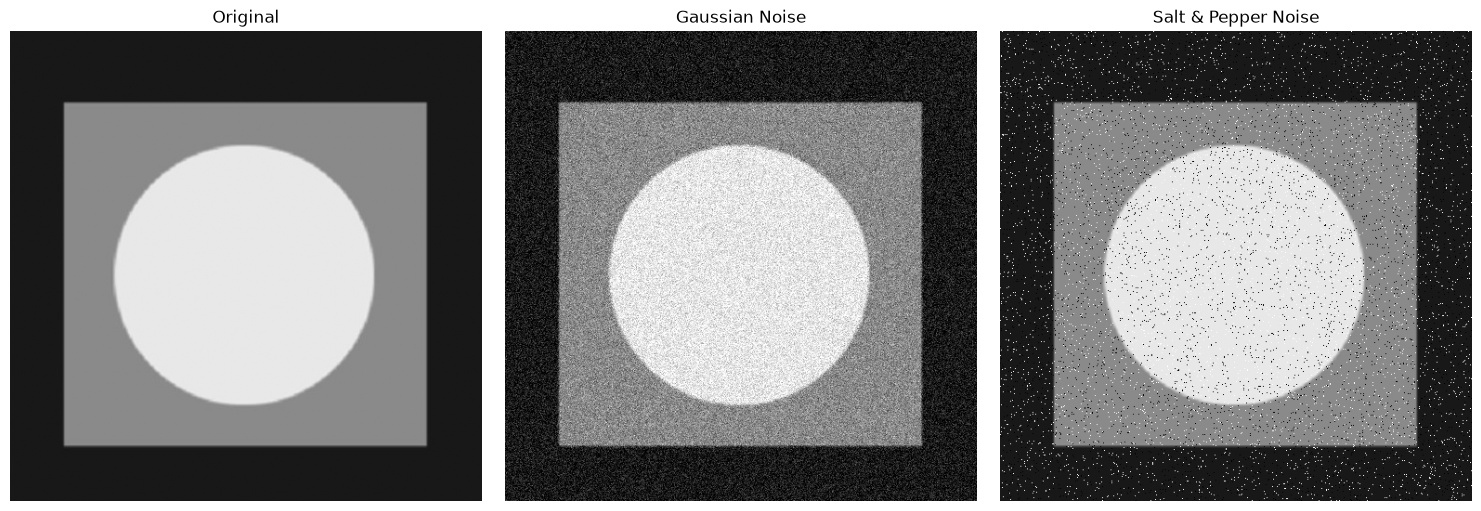

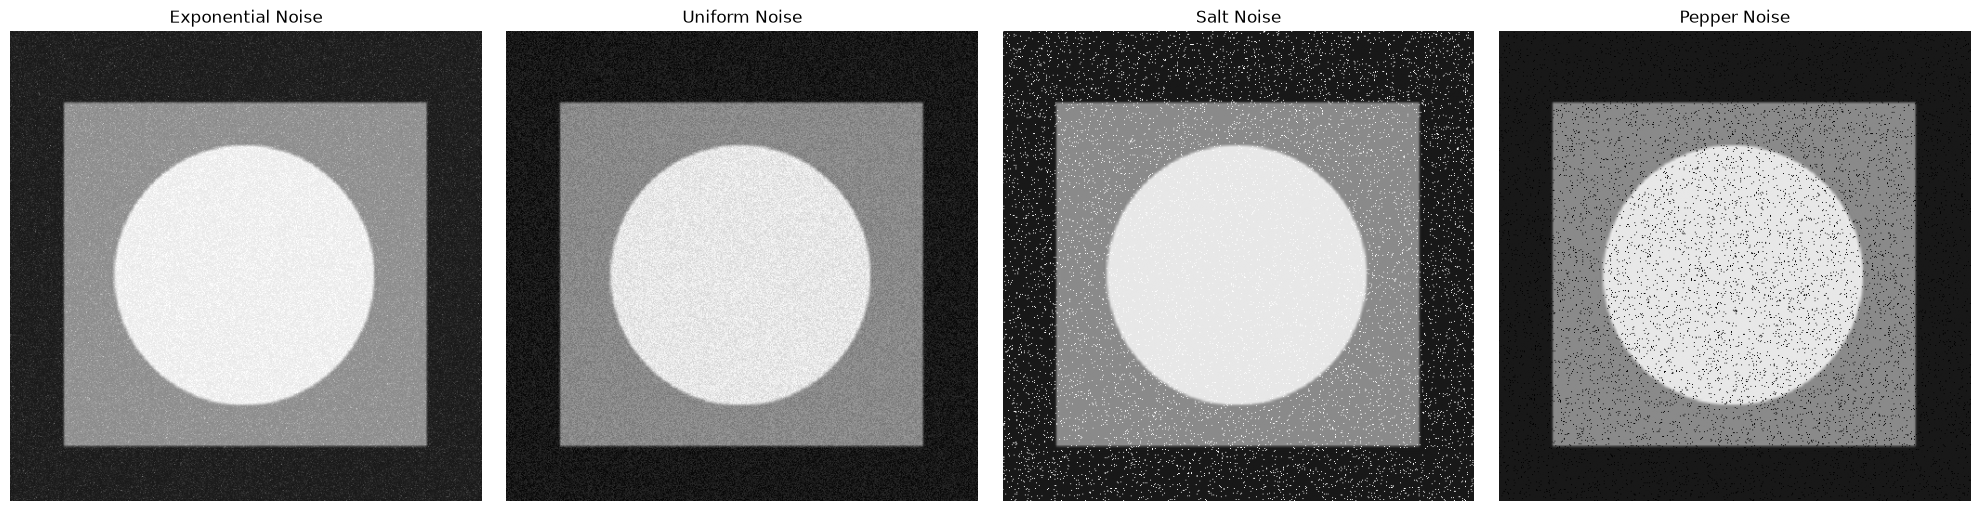

In [4]:
img = cv2.imread('images/noise.jpg', 0)

def add_noise(image, noise_type):
    row, col = image.shape
    if noise_type == 'gaussian':
        sigma = 0.01 ** 0.5
        noisy = image / 255 + np.random.normal(0, sigma, (row, col))
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)
    elif noise_type in ('salt_pepper', 'salt', 'pepper'):
        amount = 0.04
        s_vs_p = {'salt_pepper': 0.5, 'salt': 1.0, 'pepper': 0.0}[noise_type]
        noisy = np.copy(image)
        r = np.random.rand(row, col)
        noisy[r < amount * s_vs_p] = 255                      # salt
        noisy[(r >= amount * s_vs_p) & (r < amount)] = 0      # pepper
        return noisy
    elif noise_type == 'exponential':
        noisy = image + np.random.exponential(scale=10.0, size=(row, col))
        return np.clip(noisy, 0, 255).astype(np.uint8)
    elif noise_type == 'uniform':
        noisy = image + np.random.uniform(-20, 20, (row, col))
        return np.clip(noisy, 0, 255).astype(np.uint8)

noise_gauss = add_noise(img, 'gaussian')
noise_sp = add_noise(img, 'salt_pepper')
noise_expo = add_noise(img, 'exponential')
noise_uni = add_noise(img, 'uniform')
noise_salt = add_noise(img, 'salt')
noise_pepper = add_noise(img, 'pepper')

show_side_by_side([img, noise_gauss, noise_sp], ['Original', 'Gaussian Noise', 'Salt & Pepper Noise'])
show_side_by_side([noise_expo, noise_uni, noise_salt, noise_pepper],
                  ['Exponential Noise', 'Uniform Noise', 'Salt Noise', 'Pepper Noise'])

### Task#4: Arithmetic Mean Filter (built-in vs manual kernel)

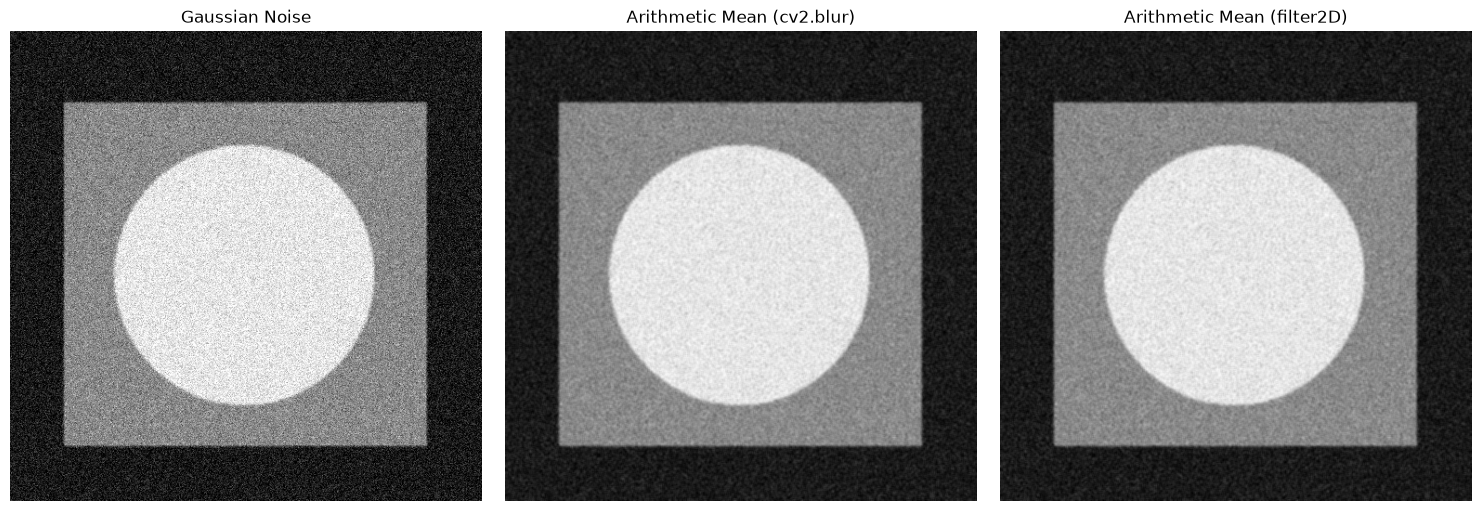

Max abs difference built-in vs manual: 0


In [5]:
k = 3
mean_builtin = cv2.blur(noise_gauss, (k, k))
mean_kernel = np.ones((k, k), np.float32) / (k * k)
mean_manual = cv2.filter2D(noise_gauss, -1, mean_kernel)

show_side_by_side([noise_gauss, mean_builtin, mean_manual],
                  ['Gaussian Noise', 'Arithmetic Mean (cv2.blur)', 'Arithmetic Mean (filter2D)'])
print('Max abs difference built-in vs manual:',
      np.abs(mean_builtin.astype(int) - mean_manual.astype(int)).max())

### Task#5: Geometric Mean Filter

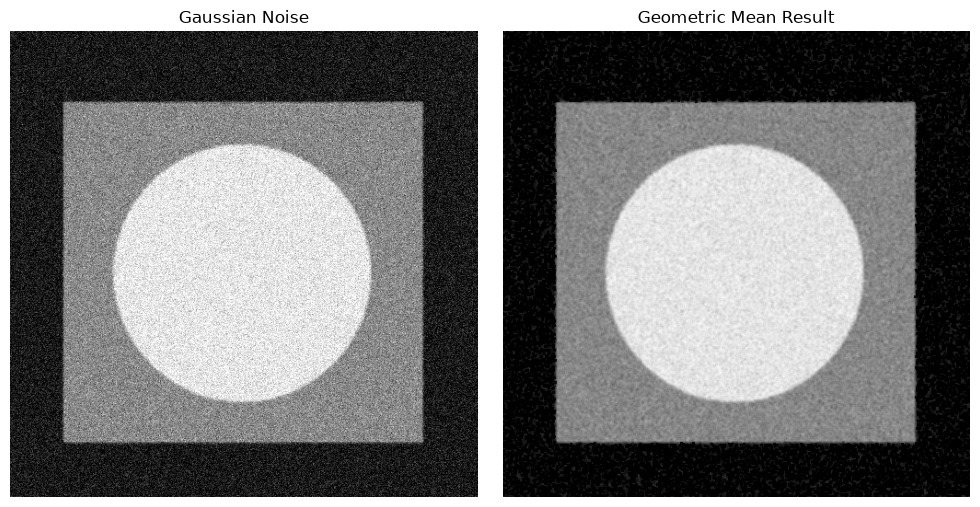

In [6]:
def geometric_mean_filter(image, kernel_size=3):
    log_img = np.log(image.astype(np.float64) + 1e-6)
    kernel = np.ones((kernel_size, kernel_size), np.float64) / kernel_size ** 2
    geo_mean = np.exp(cv2.filter2D(log_img, -1, kernel))
    return np.clip(geo_mean, 0, 255).astype(np.uint8)

show_side_by_side([noise_gauss, geometric_mean_filter(noise_gauss)],
                  ['Gaussian Noise', 'Geometric Mean Result'])

### Task#6: Harmonic Mean Filter
Works well for salt noise and Gaussian noise, fails on pepper noise.

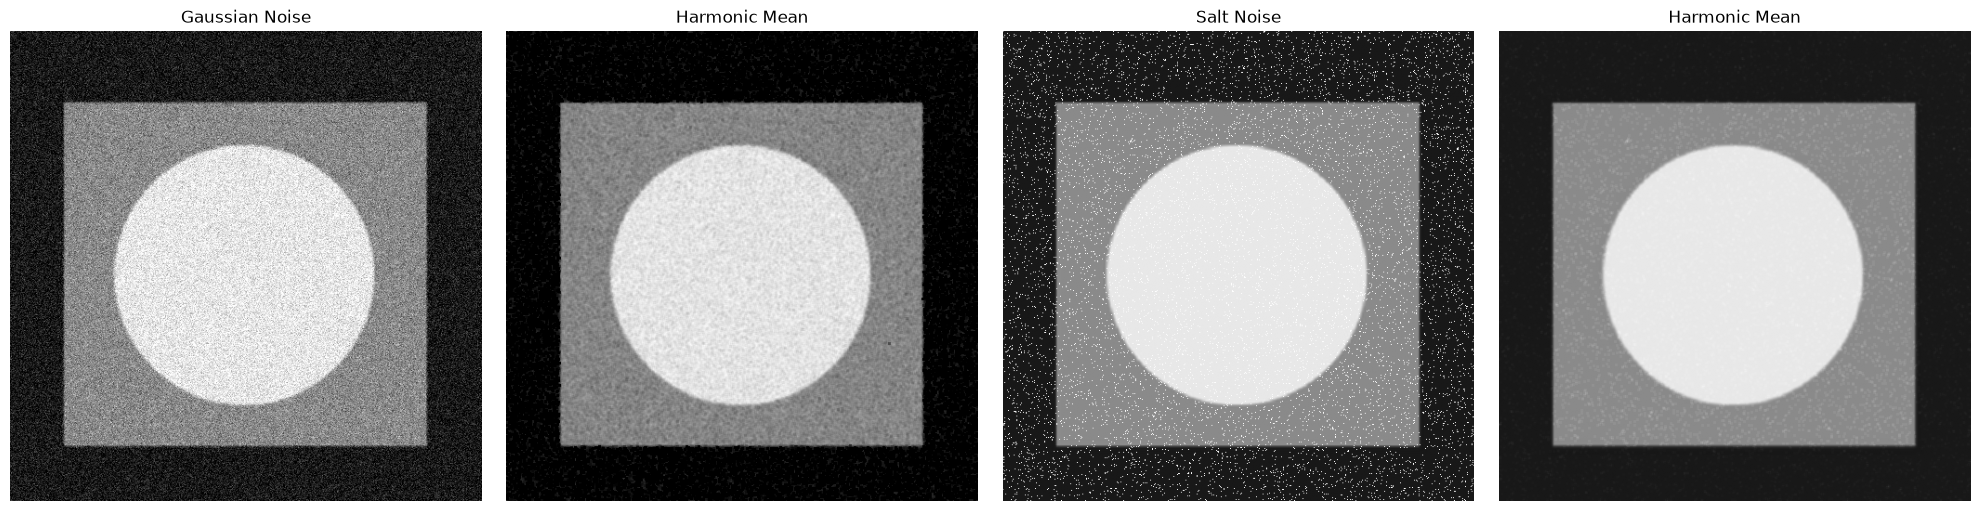

In [7]:
def harmonic_mean_filter(image, kernel_size=3):
    reciprocal = 1.0 / (image.astype(np.float64) + 1e-6)
    sum_reciprocal = cv2.filter2D(reciprocal, -1, np.ones((kernel_size, kernel_size), np.float64))
    return np.clip(kernel_size ** 2 / sum_reciprocal, 0, 255).astype(np.uint8)

show_side_by_side([noise_gauss, harmonic_mean_filter(noise_gauss),
                   noise_salt, harmonic_mean_filter(noise_salt)],
                  ['Gaussian Noise', 'Harmonic Mean', 'Salt Noise', 'Harmonic Mean'])

### Task#7: Contra-Harmonic Mean Filter
`Q > 0` removes pepper noise, `Q < 0` removes salt noise.

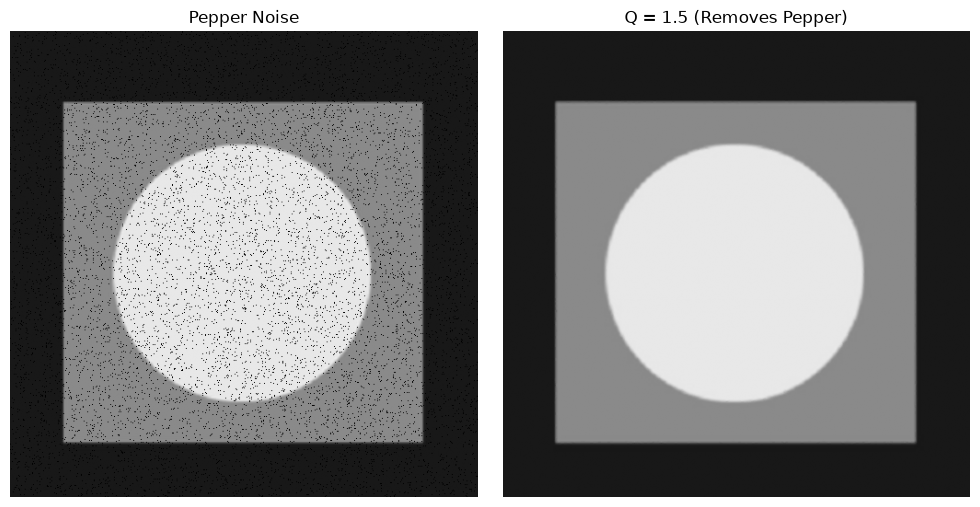

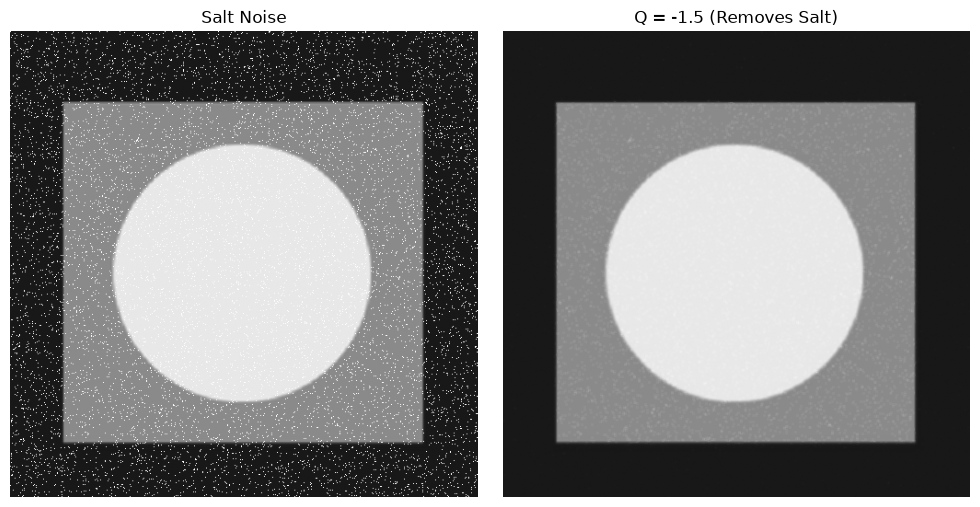

In [8]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    img_float = image.astype(np.float64) + 1e-6
    kernel = np.ones((kernel_size, kernel_size), np.float64)
    num_sum = cv2.filter2D(np.power(img_float, Q + 1), -1, kernel)
    den_sum = cv2.filter2D(np.power(img_float, Q), -1, kernel)
    return np.clip(num_sum / den_sum, 0, 255).astype(np.uint8)

show_side_by_side([noise_pepper, contra_harmonic_mean(noise_pepper, Q=1.5)],
                  ['Pepper Noise', 'Q = 1.5 (Removes Pepper)'])
show_side_by_side([noise_salt, contra_harmonic_mean(noise_salt, Q=-1.5)],
                  ['Salt Noise', 'Q = -1.5 (Removes Salt)'])

### Task#8: Median Filter
Applied to synthetic salt & pepper noise and to the provided `salt&Pepper.jpg`.

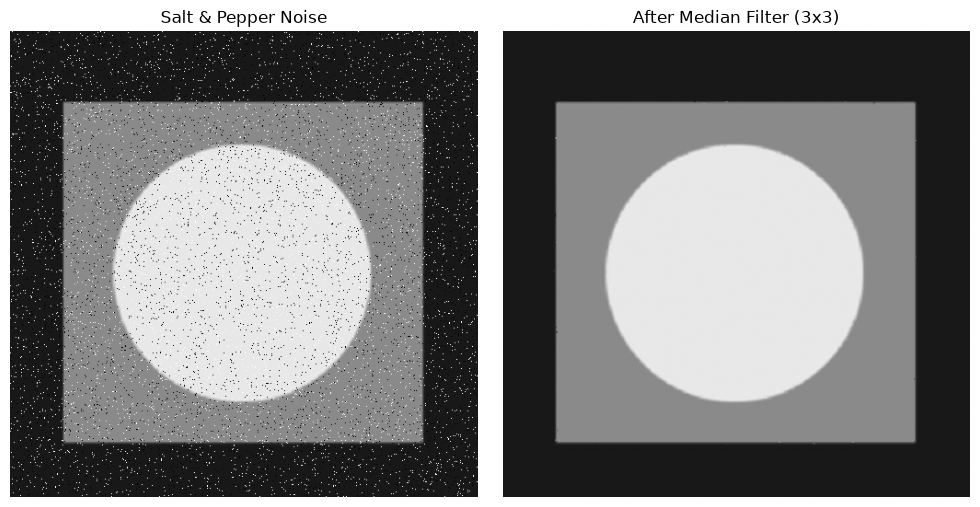

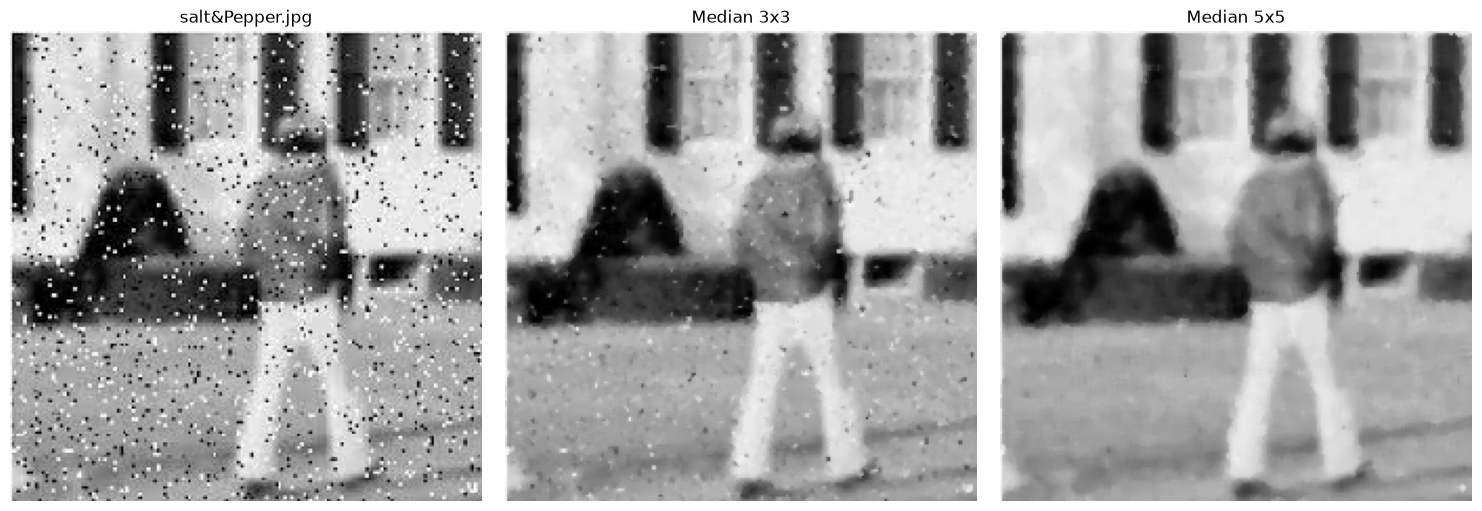

In [9]:
sp_img = cv2.imread('images/salt&Pepper.jpg', 0)

show_side_by_side([noise_sp, cv2.medianBlur(noise_sp, 3)],
                  ['Salt & Pepper Noise', 'After Median Filter (3x3)'])
show_side_by_side([sp_img, cv2.medianBlur(sp_img, 3), cv2.medianBlur(sp_img, 5)],
                  ['salt&Pepper.jpg', 'Median 3x3', 'Median 5x5'])

### Task#9: Max and Min Filters
Max (dilation) removes pepper noise; Min (erosion) removes salt noise.

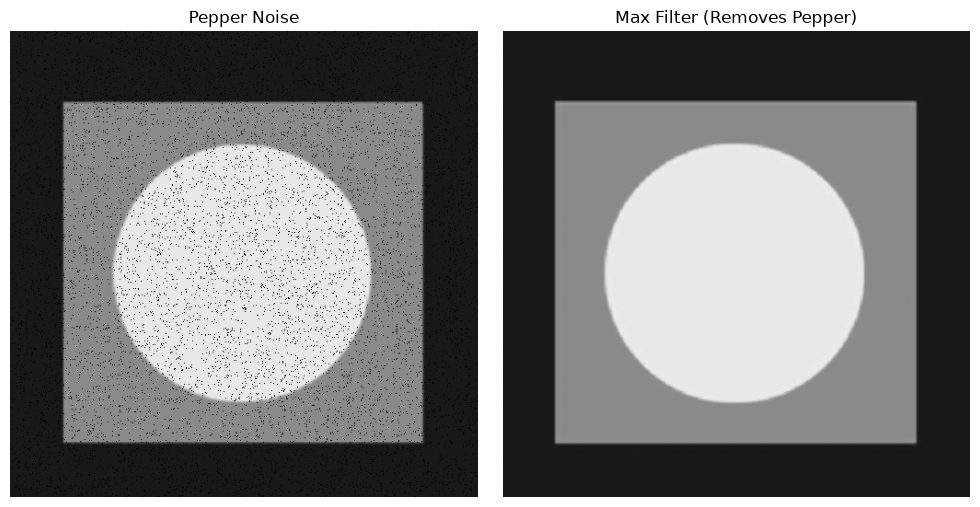

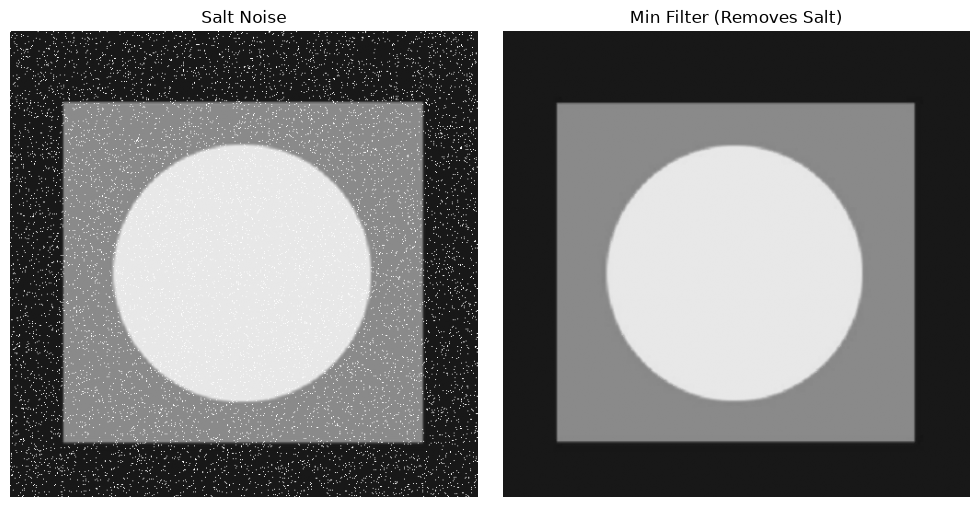

In [10]:
kernel = np.ones((3, 3), np.uint8)
show_side_by_side([noise_pepper, cv2.dilate(noise_pepper, kernel)],
                  ['Pepper Noise', 'Max Filter (Removes Pepper)'])
show_side_by_side([noise_salt, cv2.erode(noise_salt, kernel)],
                  ['Salt Noise', 'Min Filter (Removes Salt)'])

### Task#10: Midpoint Filter
Best for randomly distributed noise such as Gaussian or uniform.

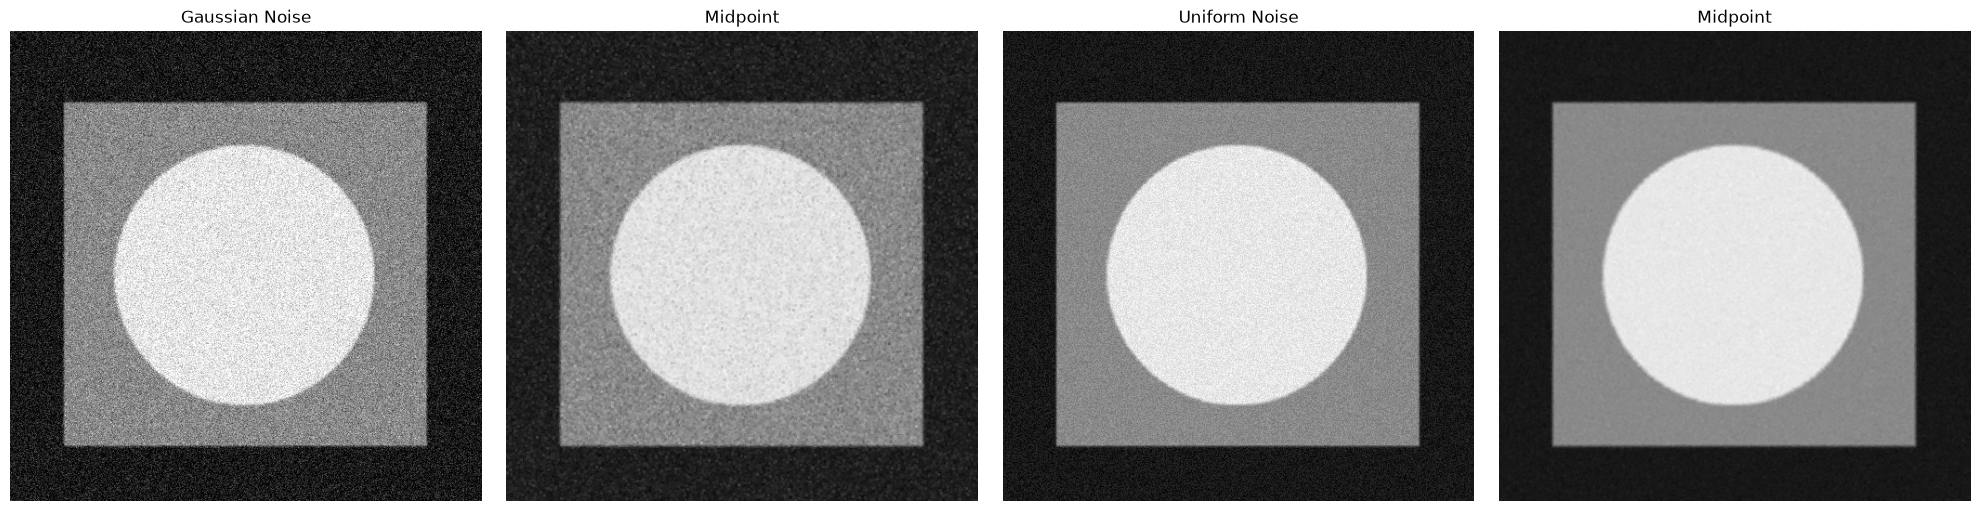

In [11]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    max_img = cv2.dilate(image, kernel).astype(np.float64)
    min_img = cv2.erode(image, kernel).astype(np.float64)
    return ((max_img + min_img) / 2).astype(np.uint8)

show_side_by_side([noise_gauss, midpoint_filter(noise_gauss), noise_uni, midpoint_filter(noise_uni)],
                  ['Gaussian Noise', 'Midpoint', 'Uniform Noise', 'Midpoint'])

### Task#11: Comparison of all filters (PSNR in dB vs. clean image)

In [12]:
filters = {
    'Arithmetic': lambda x: cv2.blur(x, (3, 3)),
    'Geometric': geometric_mean_filter,
    'Harmonic': harmonic_mean_filter,
    'Contra Q=1.5': lambda x: contra_harmonic_mean(x, Q=1.5),
    'Contra Q=-1.5': lambda x: contra_harmonic_mean(x, Q=-1.5),
    'Median': lambda x: cv2.medianBlur(x, 3),
    'Max': lambda x: cv2.dilate(x, np.ones((3, 3), np.uint8)),
    'Min': lambda x: cv2.erode(x, np.ones((3, 3), np.uint8)),
    'Midpoint': midpoint_filter,
}
noisy_set = {'Gaussian': noise_gauss, 'Uniform': noise_uni, 'Exponential': noise_expo,
             'Salt&Pepper': noise_sp, 'Salt': noise_salt, 'Pepper': noise_pepper}

print(f"{'Filter':<15}" + ''.join(f'{n:>13}' for n in noisy_set))
print(f"{'(noisy)':<15}" + ''.join(f'{cv2.PSNR(img, x):>13.2f}' for x in noisy_set.values()))
for name, f in filters.items():
    print(f'{name:<15}' + ''.join(f'{cv2.PSNR(img, f(x)):>13.2f}' for x in noisy_set.values()))

Filter              Gaussian      Uniform  Exponential  Salt&Pepper         Salt       Pepper
(noisy)                20.87        26.87        25.66        18.37        17.61        19.18
Arithmetic             30.01        35.78        28.17        27.35        25.81        27.36
Geometric              24.19        33.82        29.28        14.04        33.56        11.27
Harmonic               23.47        31.27        29.83        13.04        36.99        10.34


Contra Q=1.5           23.33        32.33        26.13        13.96        11.14        39.51
Contra Q=-1.5          23.05        29.33        30.27        13.04        38.06        10.34
Median                 27.71        32.30        30.14        50.86        45.51        47.35
Max                    16.66        23.36        18.75        11.47         8.75        32.64
Min                    17.20        22.92        33.45        13.01        32.67        10.33
Midpoint               27.15        37.14        24.97        15.54        14.85        16.40


**Conclusions:** the median filter is clearly best for salt & pepper noise; the contra-harmonic filter removes one polarity of impulse noise depending on the sign of `Q` (as do the Max/Min filters), while the arithmetic/geometric mean and midpoint filters suit Gaussian and uniform noise. Laplacian sharpening (`f - ∇²f`) enhances the crater edges of the moon image.